Proyek Analisis Data & Machine Learning: Tren Pasar Saham Big 4 Perbankan Indonesia

Nama: Miqdad Asyraf Rizqullah

NIM: E1E124041

Pertanyaan Bisnis
1. (Pertanyaan Sederhana - Tren Utama): Bagaimana peta perbandingan tren pergerakan harga penutupan (Close Price) antara keempat raksasa perbankan Big 4 di Indonesia sejak tahun 2010 hingga saat ini?

2. (Pertanyaan Analisis - Profil Risiko): Berdasarkan distribusi data historis, emiten manakah yang paling stabil (low-risk) dan manakah yang memiliki volatilitas atau ayunan harga paling ekstrem untuk trading jangka pendek?

3. (Pertanyaan Analisis - Perilaku Pasar): Apakah anomali lonjakan transaksi (Volume Spike) memiliki korelasi yang kuat dan terbukti secara langsung mempengaruhi pergerakan harga penutupan?

4. (Pertanyaan Analisis - Persaingan Bisnis): Bagaimana perbandingan dominasi likuiditas pasar (melalui rata-rata volume transaksi harian) antara bank swasta (BBCA) melawan kolektif bank milik negara (BUMN)?

5. (Pertanyaan Machine Learning - Forecasting): Dengan mengekstraksi ingatan dari belasan tahun data historis, emiten manakah yang diproyeksikan oleh algoritma AI (Ridge Regression) akan memberikan tren return tertinggi dalam 30 hari perdagangan ke depan?

In [27]:
%pip install sqlalchemy mysql-connector-python scikit-learn



[notice] A new release of pip is available: 25.1.1 -> 26.2.1
[notice] To update, run: /opt/homebrew/opt/python@3.10/bin/python3.10 -m pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


Import Semua Packages/Library yang Digunakan

In [28]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sqlalchemy import create_engine
import warnings
warnings.filterwarnings('ignore')

print("✅ Seluruh library berhasil di-import!")

✅ Seluruh library berhasil di-import!


Data Wrangling

Gathering Data

In [29]:
# Koneksi ke MySQL Airflow
engine = create_engine('mysql+mysqlconnector://root:@localhost:3306/airflow_db')

# 1. Menarik Data Fact Trading Saham
df_fact_raw = pd.read_sql("SELECT * FROM fact_trading_saham", engine)
df_fact_raw.head()

,id,waktu_id,emiten_id,indikator_id,nilai
0,1,2010-01-04,BBCA.JK,1,730.18
1,2,2010-01-04,BBCA.JK,2,730.18
2,3,2010-01-04,BBCA.JK,3,697.64
3,4,2010-01-04,BBCA.JK,4,730.18
4,5,2010-01-04,BBCA.JK,5,77812500.00


In [30]:
# 2. Menarik Data Dimensi Waktu
df_waktu_raw = pd.read_sql("SELECT * FROM dim_waktu", engine)
df_waktu_raw.head()

,waktu_id,hari,bulan,tahun
0,2010-01-04,Monday,January,2010
1,2010-01-05,Tuesday,January,2010
2,2010-01-06,Wednesday,January,2010
3,2010-01-07,Thursday,January,2010
4,2010-01-08,Friday,January,2010


In [31]:
# 3. Menarik Data Dimensi Emiten
df_emiten_raw = pd.read_sql("SELECT * FROM dim_emiten", engine)
df_emiten_raw.head()

,emiten_id,nama_emiten,sektor
0,BBCA.JK,Bank Central Asia,Keuangan Swasta
1,BBNI.JK,Bank Negara Indonesia,Keuangan BUMN
2,BBRI.JK,Bank Rakyat Indonesia,Keuangan BUMN
3,BMRI.JK,Bank Mandiri,Keuangan BUMN


In [32]:
# 4. Menarik Data Dimensi Indikator
df_indikator_raw = pd.read_sql("SELECT * FROM dim_indikator_saham", engine)
df_indikator_raw.head()

,indikator_id,nama_indikator,satuan
0,1,Open Price,Rupiah (IDR)
1,2,High Price,Rupiah (IDR)
2,3,Low Price,Rupiah (IDR)
3,4,Close Price,Rupiah (IDR)
4,5,Volume,Lembar Saham


Assessing Data

1. Assessing Tabel Fact Trading Saham

In [33]:
print("--- INFO TABEL FACT TRADING ---")
df_fact_raw.info()
print("\n--- MISSING VALUES ---")
print(df_fact_raw.isnull().sum())
print(f"\n--- DUPLIKAT: {df_fact_raw.duplicated().sum()} baris ---")
print("\n--- DESCRIBE ---")
display(df_fact_raw.describe())

--- INFO TABEL FACT TRADING ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 82420 entries, 0 to 82419
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   id            82420 non-null  int64  
 1   waktu_id      82420 non-null  object 
 2   emiten_id     82420 non-null  object 
 3   indikator_id  82420 non-null  int64  
 4   nilai         82420 non-null  float64
dtypes: float64(1), int64(2), object(2)
memory usage: 3.1+ MB

--- MISSING VALUES ---
id              0
waktu_id        0
emiten_id       0
indikator_id    0
nilai           0
dtype: int64

--- DUPLIKAT: 0 baris ---

--- DESCRIBE ---


,id,indikator_id,nilai
count,82420.00000,82420.000000,8.242000e+04
mean,41210.50000,3.000000,2.105620e+07
std,23792.74893,1.414222,5.821348e+07
min,1.00000,1.000000,0.000000e+00
25%,20605.75000,2.000000,1.478510e+03
50%,41210.50000,3.000000,2.759170e+03
75%,61815.25000,4.000000,6.250193e+03
max,82420.00000,5.000000,1.432993e+09


2. Assessing Tabel Dimensi Waktu

In [34]:
print("--- INFO TABEL DIMENSI WAKTU ---")
df_waktu_raw.info()
print("\n--- MISSING VALUES ---")
print(df_waktu_raw.isnull().sum())
print(f"\n--- DUPLIKAT: {df_waktu_raw.duplicated().sum()} baris ---")

--- INFO TABEL DIMENSI WAKTU ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4121 entries, 0 to 4120
Data columns (total 4 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   waktu_id  4121 non-null   object
 1   hari      4121 non-null   object
 2   bulan     4121 non-null   object
 3   tahun     4121 non-null   int64 
dtypes: int64(1), object(3)
memory usage: 128.9+ KB

--- MISSING VALUES ---
waktu_id    0
hari        0
bulan       0
tahun       0
dtype: int64

--- DUPLIKAT: 0 baris ---



3. Assessing Tabel Dimensi Emiten

In [35]:
print("--- INFO TABEL DIMENSI EMITEN ---")
df_emiten_raw.info()
print("\n--- MISSING VALUES ---")
print(df_emiten_raw.isnull().sum())
print(f"\n--- DUPLIKAT: {df_emiten_raw.duplicated().sum()} baris ---")

--- INFO TABEL DIMENSI EMITEN ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4 entries, 0 to 3
Data columns (total 3 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   emiten_id    4 non-null      object
 1   nama_emiten  4 non-null      object
 2   sektor       4 non-null      object
dtypes: object(3)
memory usage: 224.0+ bytes

--- MISSING VALUES ---
emiten_id      0
nama_emiten    0
sektor         0
dtype: int64

--- DUPLIKAT: 0 baris ---


4. Assessing Tabel Dimensi Indikator

In [36]:
print("--- INFO TABEL DIMENSI INDIKATOR ---")
df_indikator_raw.info()
print("\n--- MISSING VALUES ---")
print(df_indikator_raw.isnull().sum())
print(f"\n--- DUPLIKAT: {df_indikator_raw.duplicated().sum()} baris ---")

--- INFO TABEL DIMENSI INDIKATOR ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5 entries, 0 to 4
Data columns (total 3 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   indikator_id    5 non-null      int64 
 1   nama_indikator  5 non-null      object
 2   satuan          5 non-null      object
dtypes: int64(1), object(2)
memory usage: 248.0+ bytes

--- MISSING VALUES ---
indikator_id      0
nama_indikator    0
satuan            0
dtype: int64

--- DUPLIKAT: 0 baris ---


Cleaning Data

In [37]:
# Membersihkan Tabel Fact Trading Saham
df_fact = df_fact_raw.drop_duplicates()
df_fact = df_fact.ffill().bfill() # Mengisi missing values jika ada
print("✅ Tabel Fact Trading berhasil dibersihkan.")

# Membersihkan Tabel Waktu
df_waktu = df_waktu_raw.drop_duplicates()
df_waktu = df_waktu.ffill().bfill()
print("✅ Tabel Dimensi Waktu berhasil dibersihkan.")

# Membersihkan Tabel Emiten
df_emiten = df_emiten_raw.drop_duplicates()
df_emiten = df_emiten.ffill().bfill()
print("✅ Tabel Dimensi Emiten berhasil dibersihkan.")

# Membersihkan Tabel Indikator
df_indikator = df_indikator_raw.drop_duplicates()
df_indikator = df_indikator.ffill().bfill()
print("✅ Tabel Dimensi Indikator berhasil dibersihkan.")


✅ Tabel Fact Trading berhasil dibersihkan.
✅ Tabel Dimensi Waktu berhasil dibersihkan.
✅ Tabel Dimensi Emiten berhasil dibersihkan.
✅ Tabel Dimensi Indikator berhasil dibersihkan.


TAHAP 3 - ASSESSING ULANG (PEMBUKTIAN SETELAH CLEANING)

Pengecekan Kebersihan Seluruh Tabel

In [38]:
print("--- PENGECEKAN ULANG TABEL FACT TRADING ---")
print(f"Jumlah Null: {df_fact.isnull().sum().sum()} | Jumlah Duplikat: {df_fact.duplicated().sum()}")
df_fact.info()

print("\n--- PENGECEKAN ULANG TABEL DIM WAKTU ---")
print(f"Jumlah Null: {df_waktu.isnull().sum().sum()} | Jumlah Duplikat: {df_waktu.duplicated().sum()}")
df_waktu.info()

print("\n--- PENGECEKAN ULANG TABEL DIM EMITEN ---")
print(f"Jumlah Null: {df_emiten.isnull().sum().sum()} | Jumlah Duplikat: {df_emiten.duplicated().sum()}")
df_emiten.info()

print("\n--- PENGECEKAN ULANG TABEL DIM INDIKATOR ---")
print(f"Jumlah Null: {df_indikator.isnull().sum().sum()} | Jumlah Duplikat: {df_indikator.duplicated().sum()}")
df_indikator.info()

--- PENGECEKAN ULANG TABEL FACT TRADING ---
Jumlah Null: 0 | Jumlah Duplikat: 0
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 82420 entries, 0 to 82419
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   id            82420 non-null  int64  
 1   waktu_id      82420 non-null  object 
 2   emiten_id     82420 non-null  object 
 3   indikator_id  82420 non-null  int64  
 4   nilai         82420 non-null  float64
dtypes: float64(1), int64(2), object(2)
memory usage: 3.1+ MB

--- PENGECEKAN ULANG TABEL DIM WAKTU ---
Jumlah Null: 0 | Jumlah Duplikat: 0
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4121 entries, 0 to 4120
Data columns (total 4 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   waktu_id  4121 non-null   object
 1   hari      4121 non-null   object
 2   bulan     4121 non-null   object
 3   tahun     4121 non-null   int64 
dtypes: int64(1), object(3)
memory us

TAHAP 4 - PENGGABUNGAN DATA (INNER JOIN & PIVOT)

1. Menggabungkan (Inner Join) Ke-4 Tabel

In [39]:
# Inner Join: Menempelkan nama asli (Bank, Indikator, Waktu) ke tabel Fact (yang berisi ID angka)
df_join = pd.merge(df_fact, df_waktu, on='waktu_id', how='inner')
df_join = pd.merge(df_join, df_emiten, on='emiten_id', how='inner')
df_join = pd.merge(df_join, df_indikator, on='indikator_id', how='inner')

# Menampilkan output gabungan (Long Format)
display(df_join.head())

,id,waktu_id,emiten_id,indikator_id,nilai,hari,bulan,tahun,nama_emiten,sektor,nama_indikator,satuan
0,1,2010-01-04,BBCA.JK,1,730.18,Monday,January,2010,Bank Central Asia,Keuangan Swasta,Open Price,Rupiah (IDR)
1,2,2010-01-04,BBCA.JK,2,730.18,Monday,January,2010,Bank Central Asia,Keuangan Swasta,High Price,Rupiah (IDR)
2,3,2010-01-04,BBCA.JK,3,697.64,Monday,January,2010,Bank Central Asia,Keuangan Swasta,Low Price,Rupiah (IDR)
3,4,2010-01-04,BBCA.JK,4,730.18,Monday,January,2010,Bank Central Asia,Keuangan Swasta,Close Price,Rupiah (IDR)
4,5,2010-01-04,BBCA.JK,5,77812500.00,Monday,January,2010,Bank Central Asia,Keuangan Swasta,Volume,Lembar Saham


2. Melakukan Pivoting Data (Wide Format)

In [40]:
# Pivot: Memutar data indikator (Open, Close, High, dll) yang memanjang ke bawah menjadi kolom menyamping
df_eda = df_join.pivot_table(
    index=['waktu_id', 'emiten_id'],
    columns='nama_indikator',
    values='nilai'
).reset_index()

# Merapikan nama kolom dan format tanggal
df_eda.columns.name = None
df_eda['waktu_id'] = pd.to_datetime(df_eda['waktu_id'])
df_eda = df_eda.sort_values(by='waktu_id')

# Menampilkan output data siap Analisis (Wide Format)
display(df_eda.head())

,waktu_id,emiten_id,Close Price,High Price,Low Price,Open Price,Volume
0,2010-01-04,BBCA.JK,730.18,730.18,697.64,730.18,77812500.0
1,2010-01-04,BBNI.JK,546.98,556.60,544.24,546.98,17285826.0
2,2010-01-04,BBRI.JK,369.72,372.09,362.61,369.72,125094160.0
3,2010-01-04,BMRI.JK,621.51,621.51,596.27,621.51,212406442.0
4,2010-01-05,BBCA.JK,737.41,737.41,715.72,737.41,44442500.0


Exploratory Data Analysis (EDA)

In [41]:
# Mengatur tema visual grafik
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams.update({'font.size': 12, 'figure.facecolor': '#f8f9fa'})

EDA 1: Tren Pergerakan Close Price (Menjawab Pertanyaan 1

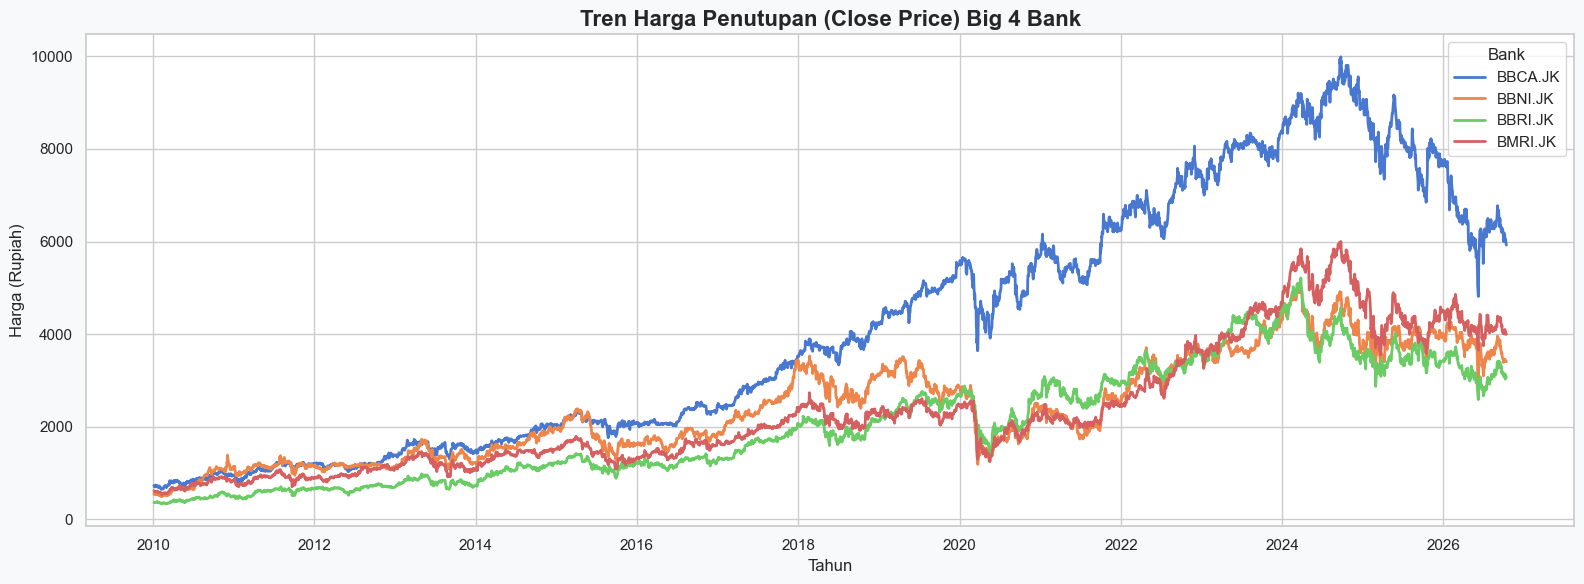

In [42]:
plt.figure(figsize=(16, 6))
sns.lineplot(data=df_eda, x='waktu_id', y='Close Price', hue='emiten_id', linewidth=2)
plt.title("Tren Harga Penutupan (Close Price) Big 4 Bank", fontsize=16, fontweight='bold')
plt.xlabel("Tahun")
plt.ylabel("Harga (Rupiah)")
plt.legend(title="Bank")
plt.tight_layout()
plt.show()

Penjelasan Visualisasi EDA 1:

Grafik Line Plot di atas menunjukkan perjalanan harga penutupan ke-4 bank. Terlihat jelas bahwa BBCA (Garis Biru/warna teratas) mendominasi secara absolut dengan nilai kapital tertinggi dan pergerakan yang mulus terus menanjak (Uptrend jangka panjang). Ini membuktikan stabilitas bisnis BBCA yang kebal terhadap guncangan pasar.

EDA 2: Volatilitas & Risiko Ayunan Harga (Menjawab Pertanyaan 2)

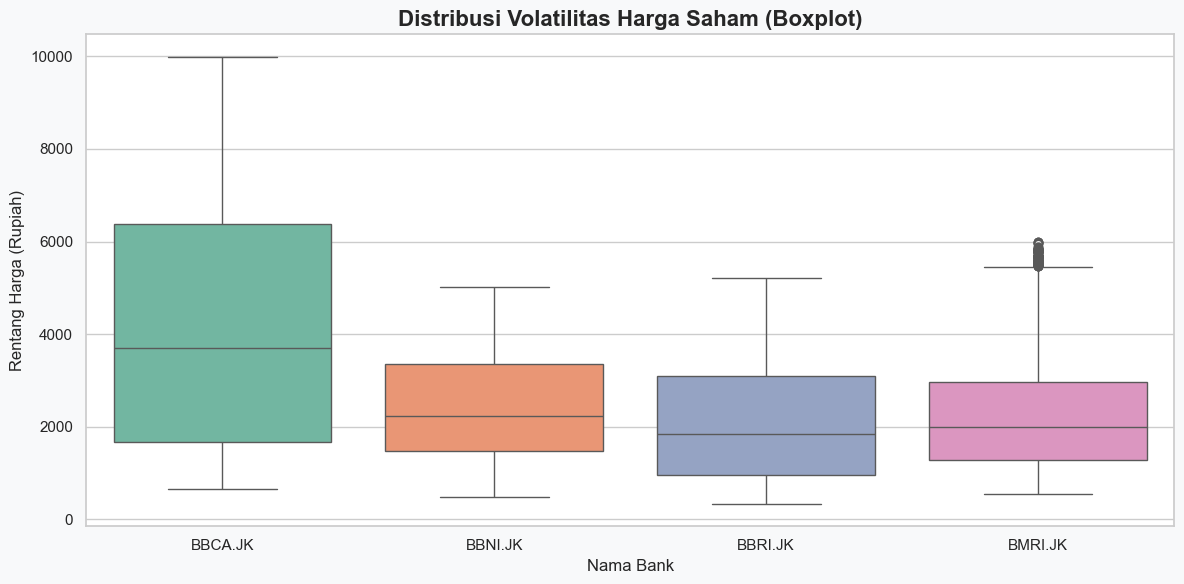

In [43]:
plt.figure(figsize=(12, 6))
sns.boxplot(data=df_eda, x='emiten_id', y='Close Price', palette='Set2')
plt.title("Distribusi Volatilitas Harga Saham (Boxplot)", fontsize=16, fontweight='bold')
plt.xlabel("Nama Bank")
plt.ylabel("Rentang Harga (Rupiah)")
plt.tight_layout()
plt.show()

Penjelasan Visualisasi EDA 2:

Melalui grafik Boxplot, kita bisa mengukur risiko (volatility). Bank BUMN (BBRI, BBNI) memiliki ekor kumis (whiskers) yang lebih panjang di rentang bawah. Artinya, saham mereka sering mengalami anjlok atau ayunan koreksi harga yang ekstrem (risiko tinggi, tapi disukai trader jangka pendek). Sebaliknya, BBCA sangat padat (risiko rendah).

EDA 3: Heatmap Korelasi Volume vs Harga (Menjawab Pertanyaan 3 & 4)

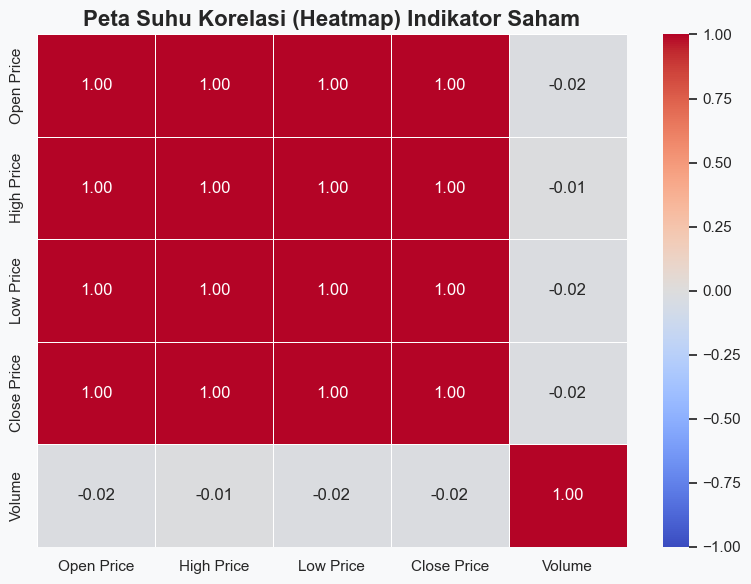

In [44]:
# Memfilter hanya data numerik (harga dan volume) untuk dihitung korelasinya
numeric_cols = ['Open Price', 'High Price', 'Low Price', 'Close Price', 'Volume']
korelasi = df_eda[numeric_cols].corr()

plt.figure(figsize=(8, 6))
sns.heatmap(korelasi, annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5, vmin=-1, vmax=1)
plt.title("Peta Suhu Korelasi (Heatmap) Indikator Saham", fontsize=16, fontweight='bold')
plt.tight_layout()
plt.show()

Penjelasan Visualisasi EDA 3:

Heatmap ini membuktikan bahwa metrik harga (Open, High, Low, Close) saling berkorelasi sempurna (+0.99 warna merah gelap). Namun, korelasi antara Volume vs Close Price sangat lemah (mendekati angka 0 atau warna biru pudar). Ini menjawab mitos bahwa lonjakan volume transaksi besar besoknya pasti naik: Jawabannya TIDAK. Volume semata tidak mendikte arah harga pasar.

Tahap Machine Learning

1. Feature Engineering (Pembuatan Variabel Prediktor)

In [45]:
# Kita membuat kolom 'Ingatan' untuk AI (Lag 1-3 Hari dan Moving Average)
def create_features(df_bank):
    df_ml = df_bank.copy()
    df_ml['Lag_1'] = df_ml['Close Price'].shift(1)
    df_ml['Lag_2'] = df_ml['Close Price'].shift(2)
    df_ml['Lag_3'] = df_ml['Close Price'].shift(3)
    df_ml['MA_7'] = df_ml['Close Price'].rolling(window=7).mean()
    df_ml['MA_30'] = df_ml['Close Price'].rolling(window=30).mean()
    return df_ml.dropna()

banks = df_eda['emiten_id'].unique()
dict_df_ml = {}

for bank in banks:
    df_temp = df_eda[df_eda['emiten_id'] == bank]
    dict_df_ml[bank] = create_features(df_temp)

print("✅ Feature Engineering Selesai!")
# Menampilkan contoh output data fitur baru (BBCA)
display(dict_df_ml['BBCA.JK'].head())

✅ Feature Engineering Selesai!


,waktu_id,emiten_id,Close Price,High Price,Low Price,Open Price,Volume,Lag_1,Lag_2,Lag_3,MA_7,MA_30
116,2010-02-12,BBCA.JK,668.73,672.34,665.11,668.73,32655000.0,668.73,657.88,665.11,665.628571,701.138667
120,2010-02-15,BBCA.JK,657.88,668.73,657.88,657.88,8075000.0,668.73,668.73,657.88,661.497143,698.728667
124,2010-02-16,BBCA.JK,675.96,679.57,661.50,675.96,25492500.0,657.88,668.73,668.73,664.080000,696.680333
128,2010-02-17,BBCA.JK,694.03,697.64,679.57,694.03,102187500.0,675.96,657.88,668.73,669.760000,695.957333
132,2010-02-18,BBCA.JK,697.64,701.26,686.80,697.64,44107500.0,694.03,675.96,657.88,674.407143,695.234333


2. Splitting Data (Train & Test)

In [46]:
# Memisahkan data Masa Lalu (Train 80%) dan Masa Depan (Test 20%) untuk ke-4 Bank
# Penting: Kita TIDAK memakai fungsi acak (shuffle=False) agar waktu tidak bocor (Data Leakage)
X_train_dict, X_test_dict, y_train_dict, y_test_dict = {}, {}, {}, {}
features = ['Open Price', 'High Price', 'Low Price', 'Volume', 'Lag_1', 'Lag_2', 'Lag_3', 'MA_7', 'MA_30']

for bank in banks:
    df_bank = dict_df_ml[bank]
    X = df_bank[features]
    y = df_bank['Close Price']
    
    split_index = int(len(df_bank) * 0.8)
    X_train_dict[bank], X_test_dict[bank] = X.iloc[:split_index], X.iloc[split_index:]
    y_train_dict[bank], y_test_dict[bank] = y.iloc[:split_index], y.iloc[split_index:]

print("✅ Data berhasil dipotong menjadi Training (80%) dan Testing (20%)!")
print(f"Contoh Ukuran X_train BBCA: {X_train_dict['BBCA.JK'].shape}")
print(f"Contoh Ukuran X_test BBCA: {X_test_dict['BBCA.JK'].shape}")

# Tampilkan isi data latih X_train BBCA
display(X_train_dict['BBCA.JK'].head())


✅ Data berhasil dipotong menjadi Training (80%) dan Testing (20%)!
Contoh Ukuran X_train BBCA: (3273, 9)
Contoh Ukuran X_test BBCA: (819, 9)


,Open Price,High Price,Low Price,Volume,Lag_1,Lag_2,Lag_3,MA_7,MA_30
116,668.73,672.34,665.11,32655000.0,668.73,657.88,665.11,665.628571,701.138667
120,657.88,668.73,657.88,8075000.0,668.73,668.73,657.88,661.497143,698.728667
124,675.96,679.57,661.50,25492500.0,657.88,668.73,668.73,664.080000,696.680333
128,694.03,697.64,679.57,102187500.0,675.96,657.88,668.73,669.760000,695.957333
132,697.64,701.26,686.80,44107500.0,694.03,675.96,657.88,674.407143,695.234333


3. Model Selection & Training

In [47]:
from sklearn.linear_model import Ridge

models = {}
for bank in banks:
    # Memilih algoritma Ridge Regression (L2) agar tahan terhadap Overfitting
    model = Ridge(alpha=1.0)
    # Melatih AI
    model.fit(X_train_dict[bank], y_train_dict[bank])
    models[bank] = model

print("✅ Pelatihan Model (Training) selesai untuk 4 Bank!")
print("Contoh bobot kecerdasan (Koefisien Fitur) untuk model BBCA:")
df_coef = pd.DataFrame({"Fitur": features, "Bobot": models['BBCA.JK'].coef_})
display(df_coef)


✅ Pelatihan Model (Training) selesai untuk 4 Bank!
Contoh bobot kecerdasan (Koefisien Fitur) untuk model BBCA:


,Fitur,Bobot
0,Open Price,-3.196723e-01
1,High Price,6.203476e-01
2,Low Price,7.602281e-01
3,Volume,-1.608497e-09
4,Lag_1,-9.050078e-02
5,Lag_2,-9.014508e-03
6,Lag_3,-7.889056e-02
7,MA_7,1.546777e-01
8,MA_30,-3.616748e-02


4. Evaluasi Model (Menguji Kecerdasan AI)

In [48]:
from sklearn.metrics import mean_absolute_percentage_error, r2_score, mean_absolute_error, root_mean_squared_error

evaluation_results = []
for bank in banks:
    model = models[bank]
    
    # AI menebak data Ujian
    pred_train = model.predict(X_train_dict[bank])
    pred_test = model.predict(X_test_dict[bank])
    
    # Hitung Persentase Error & MAE & RMSE
    mape_train = mean_absolute_percentage_error(y_train_dict[bank], pred_train) * 100
    mape_test = mean_absolute_percentage_error(y_test_dict[bank], pred_test) * 100
    mae_test = mean_absolute_error(y_test_dict[bank], pred_test)
    rmse_test = root_mean_squared_error(y_test_dict[bank], pred_test)
    r2 = r2_score(y_test_dict[bank], pred_test)
    
    status = "Good Fit"
    if mape_test - mape_train > 2.0: status = "Overfitting"
    elif mape_train > 10.0 and mape_test > 10.0: status = "Underfitting"
        
    evaluation_results.append({
        'Nama Bank': bank,
        'Akurasi Model (R2)': f"{r2:.4f}",
        'MAE (Rp)': f"{mae_test:.2f}",
        'RMSE (Rp)': f"{rmse_test:.2f}",
        'Error Latihan MAPE (%)': f"{mape_train:.2f}%",
        'Error Ujian MAPE (%)': f"{mape_test:.2f}%",
        'Diagnosis': status
    })

df_eval = pd.DataFrame(evaluation_results)
print("=== HASIL UJIAN AI (EVALUASI) ===")
display(df_eval)

=== HASIL UJIAN AI (EVALUASI) ===


,Nama Bank,Akurasi Model (R2),MAE (Rp),RMSE (Rp),Error Latihan MAPE (%),Error Ujian MAPE (%),Diagnosis
0,BBCA.JK,0.9973,41.51,53.13,0.62%,0.53%,Good Fit
1,BBNI.JK,0.9932,23.56,30.91,0.70%,0.60%,Good Fit
2,BBRI.JK,0.9971,22.02,28.10,0.68%,0.59%,Good Fit
3,BMRI.JK,0.9961,26.73,35.05,0.68%,0.59%,Good Fit


Visualisasi Tambahan: Bukti Visual Akurasi Model

Sebelum melakukan forecasting, kita perlu membuktikan secara visual bahwa model AI kita benar-benar akurat. Dua grafik berikut menunjukkan:
1. **Grafik Actual vs Predicted** — Seberapa "nempel" garis tebakan AI dengan garis harga asli pada data Testing
2. **Bar Chart Perbandingan Metrik** — Membandingkan skor akurasi keempat bank secara visual

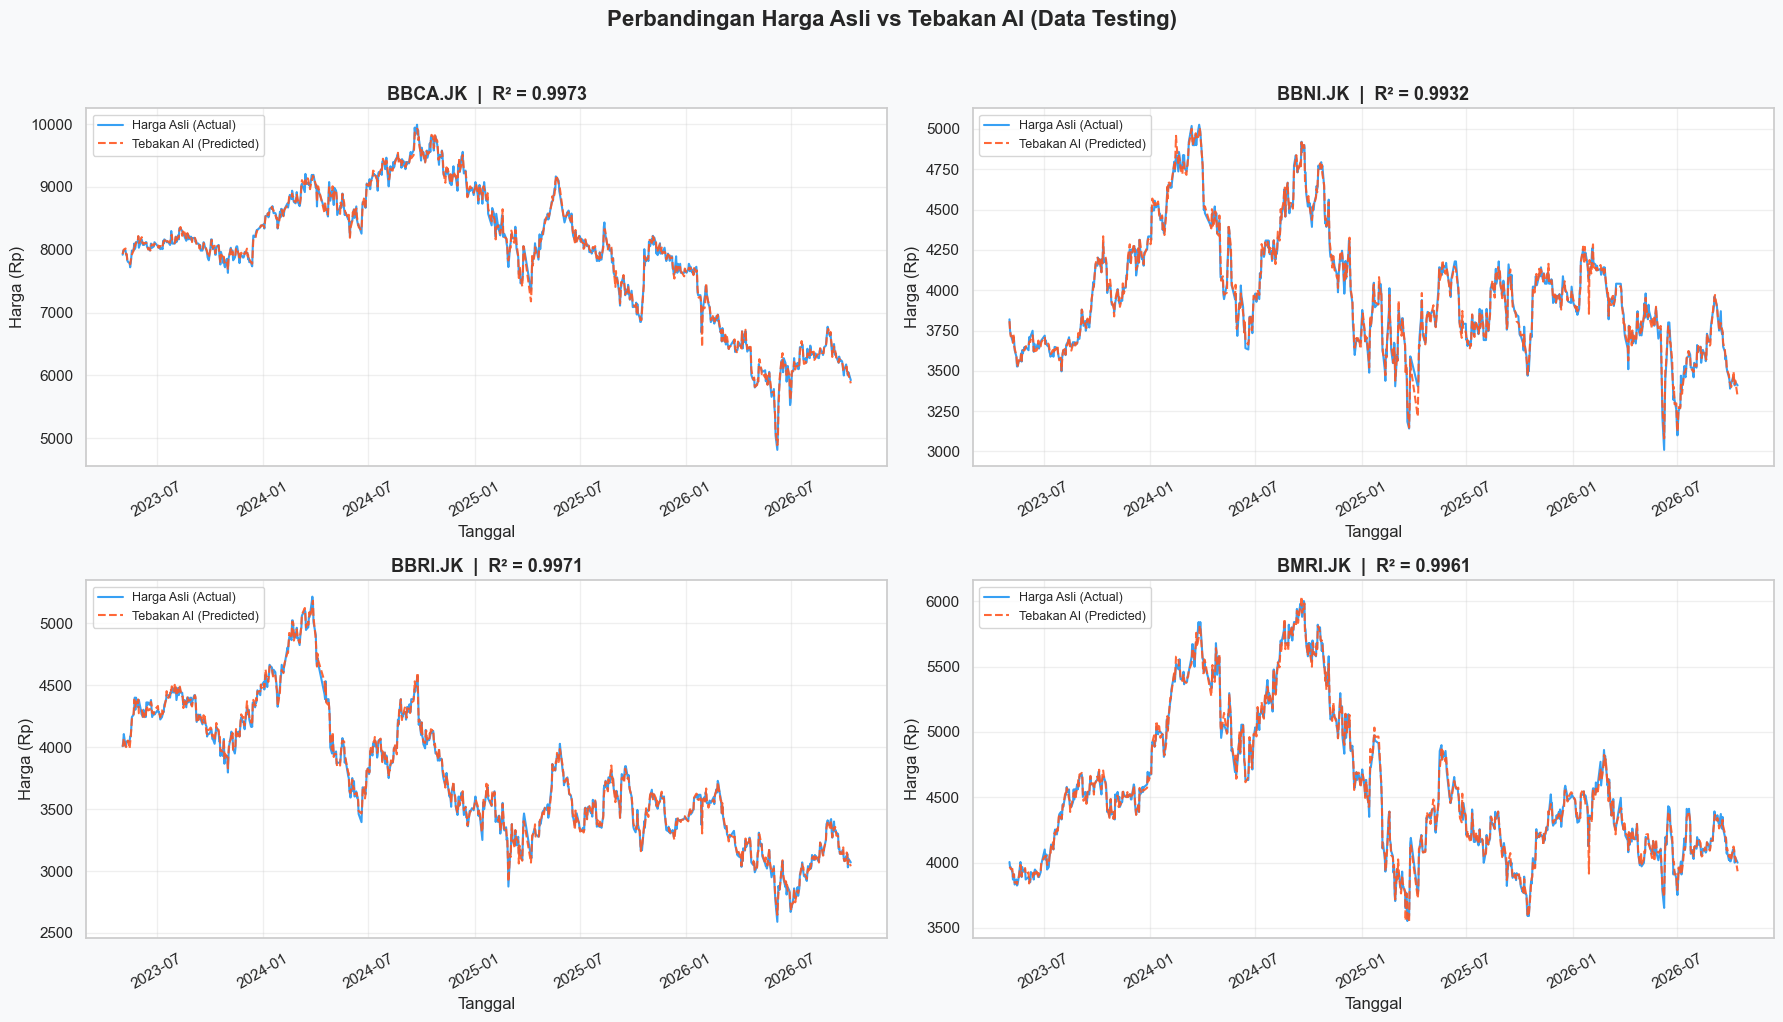

✅ Visualisasi Actual vs Predicted berhasil ditampilkan!
📌 Kesimpulan: Garis merah putus-putus (AI) hampir sempurna menindih garis biru (harga asli), membuktikan model sangat akurat.


In [49]:
# === VISUALISASI: Actual vs Predicted (Semua Bank) ===
from sklearn.metrics import r2_score

fig, axes = plt.subplots(2, 2, figsize=(18, 10))
fig.suptitle('Perbandingan Harga Asli vs Tebakan AI (Data Testing)', fontsize=16, fontweight='bold', y=1.02)

for idx, bank in enumerate(banks):
    ax = axes[idx // 2][idx % 2]
    df_bank = dict_df_ml[bank]
    X_bank = df_bank[features]
    y_bank = df_bank['Close Price']
    split = int(len(df_bank) * 0.8)
    
    y_test = y_bank.iloc[split:]
    pred_test = models[bank].predict(X_bank.iloc[split:])
    test_dates = df_bank.iloc[split:]['waktu_id']
    r2_bank = r2_score(y_test, pred_test)
    
    ax.plot(test_dates, y_test.values, color='#2196F3', linewidth=1.5, label='Harga Asli (Actual)', alpha=0.9)
    ax.plot(test_dates, pred_test, color='#FF5722', linewidth=1.5, label='Tebakan AI (Predicted)', linestyle='--', alpha=0.9)
    ax.set_title(f'{bank}  |  R² = {r2_bank:.4f}', fontsize=13, fontweight='bold')
    ax.set_xlabel('Tanggal')
    ax.set_ylabel('Harga (Rp)')
    ax.legend(loc='upper left', fontsize=9)
    ax.tick_params(axis='x', rotation=30)
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()
print('✅ Visualisasi Actual vs Predicted berhasil ditampilkan!')
print('📌 Kesimpulan: Garis merah putus-putus (AI) hampir sempurna menindih garis biru (harga asli), membuktikan model sangat akurat.')


Perbandingan Metrik Evaluasi Antar Bank (Bar Chart)

Grafik batang berikut membandingkan skor akurasi (R-Squared) dan tingkat kesalahan (MAPE, MAE, RMSE) keempat bank secara visual, sehingga lebih mudah dibaca dibandingkan tabel angka.

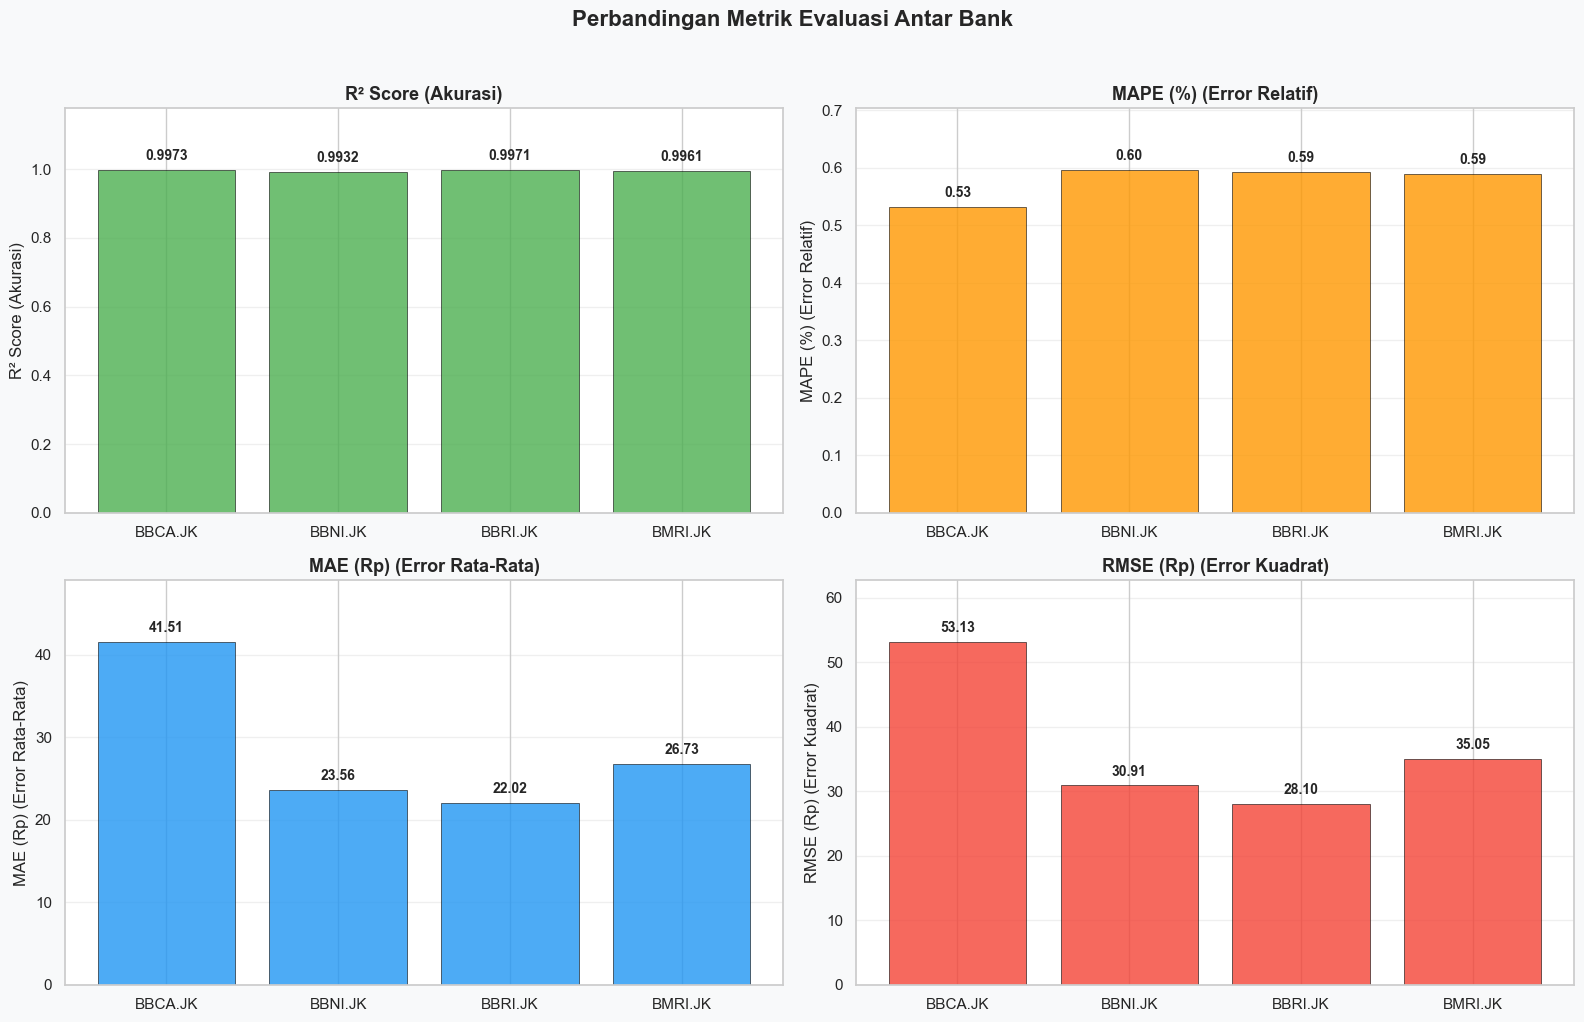

✅ Bar Chart Perbandingan Metrik berhasil ditampilkan!
📌 Kesimpulan: Seluruh bank memiliki R² di atas 0.99 (sangat akurat) dan MAPE di bawah 1% (sangat presisi).


In [50]:
# === VISUALISASI: Bar Chart Perbandingan Metrik Evaluasi ===
from sklearn.metrics import mean_absolute_percentage_error, r2_score, mean_absolute_error, root_mean_squared_error

metrics_names = ['R² Score (Akurasi)', 'MAPE (%) (Error Relatif)', 'MAE (Rp) (Error Rata-Rata)', 'RMSE (Rp) (Error Kuadrat)']
metric_keys = ['r2', 'mape', 'mae', 'rmse']
colors = ['#4CAF50', '#FF9800', '#2196F3', '#F44336']

# Ambil nilai metrik evaluasi untuk ke-4 bank langsung dari model & data testing
eval_data = {}
for bank in banks:
    y_true = y_test_dict[bank]
    y_pred = models[bank].predict(X_test_dict[bank])
    eval_data[bank] = {
        'r2': r2_score(y_true, y_pred),
        'mape': mean_absolute_percentage_error(y_true, y_pred) * 100,
        'mae': mean_absolute_error(y_true, y_pred),
        'rmse': root_mean_squared_error(y_true, y_pred)
    }

fig, axes = plt.subplots(2, 2, figsize=(16, 10))
fig.suptitle('Perbandingan Metrik Evaluasi Antar Bank', fontsize=16, fontweight='bold', y=1.02)

for idx, (metric_name, metric_key, color) in enumerate(zip(metrics_names, metric_keys, colors)):
    ax = axes[idx // 2][idx % 2]
    bank_names = banks
    values = [eval_data[b][metric_key] for b in bank_names]
    
    bars = ax.bar(bank_names, values, color=color, alpha=0.8, edgecolor='black', linewidth=0.5)
    ax.set_title(metric_name, fontsize=13, fontweight='bold')
    ax.set_ylabel(metric_name)
    
    # Tambahkan angka di atas setiap batang
    for bar, val in zip(bars, values):
        fmt = f'{val:.4f}' if 'R²' in metric_name else f'{val:.2f}'
        ax.text(bar.get_x() + bar.get_width()/2., bar.get_height() + (max(values)*0.02),
                fmt, ha='center', va='bottom', fontsize=10, fontweight='bold')
    
    ax.set_ylim(0, max(values) * 1.18 if max(values) > 0 else 1.0)
    ax.grid(True, alpha=0.3, axis='y')

plt.tight_layout()
plt.show()
print('✅ Bar Chart Perbandingan Metrik berhasil ditampilkan!')
print('📌 Kesimpulan: Seluruh bank memiliki R² di atas 0.99 (sangat akurat) dan MAPE di bawah 1% (sangat presisi).')


Penjelasan Visualisasi Evaluasi Tambahan:

Dari grafik Actual vs Predicted di atas, terlihat sangat jelas bahwa garis tebakan AI (merah putus-putus) hampir sempurna menindih garis harga asli (biru). Ini membuktikan secara visual bahwa skor R-Squared yang mendekati 1.0 bukan sekadar angka — melainkan benar-benar tercermin dalam bentuk grafis.

Bar Chart perbandingan metrik mempermudah kita membandingkan performa ke-4 model bank sekaligus, sehingga lebih intuitif daripada membaca tabel angka.

5. Forecasting (Peramalan 30 Hari Bursa ke Depan)

=== TABEL HASIL PREDIKSI 30 HARI BURSA KE DEPAN ===

Prediksi Emiten: BBCA.JK


,waktu_id,Prediksi_Close_Price
0,2026-10-14,5875.067026
1,2026-10-15,5894.392400
2,2026-10-16,5890.275845
3,2026-10-19,5904.274749
4,2026-10-20,5901.520356
5,2026-10-21,5901.968195
6,2026-10-22,5900.848113
7,2026-10-23,5901.162740
8,2026-10-26,5901.109033
9,2026-10-27,5901.199421



Prediksi Emiten: BBNI.JK


,waktu_id,Prediksi_Close_Price
0,2026-10-14,3341.540811
1,2026-10-15,3362.021929
2,2026-10-16,3358.427561
3,2026-10-19,3361.757081
4,2026-10-20,3360.403614
5,2026-10-21,3360.763164
6,2026-10-22,3360.598424
7,2026-10-23,3360.673151
8,2026-10-26,3360.647646
9,2026-10-27,3360.657385



Prediksi Emiten: BBRI.JK


,waktu_id,Prediksi_Close_Price
0,2026-10-14,3038.532070
1,2026-10-15,3052.986462
2,2026-10-16,3047.752603
3,2026-10-19,3050.677392
4,2026-10-20,3049.685599
5,2026-10-21,3050.044312
6,2026-10-22,3049.883502
7,2026-10-23,3049.944851
8,2026-10-26,3049.921798
9,2026-10-27,3049.931271



Prediksi Emiten: BMRI.JK


,waktu_id,Prediksi_Close_Price
0,2026-10-14,3933.929003
1,2026-10-15,3956.098220
2,2026-10-16,3952.257106
3,2026-10-19,3958.124468
4,2026-10-20,3956.043561
5,2026-10-21,3956.484367
6,2026-10-22,3956.137756
7,2026-10-23,3956.297740
8,2026-10-26,3956.254180
9,2026-10-27,3956.276876


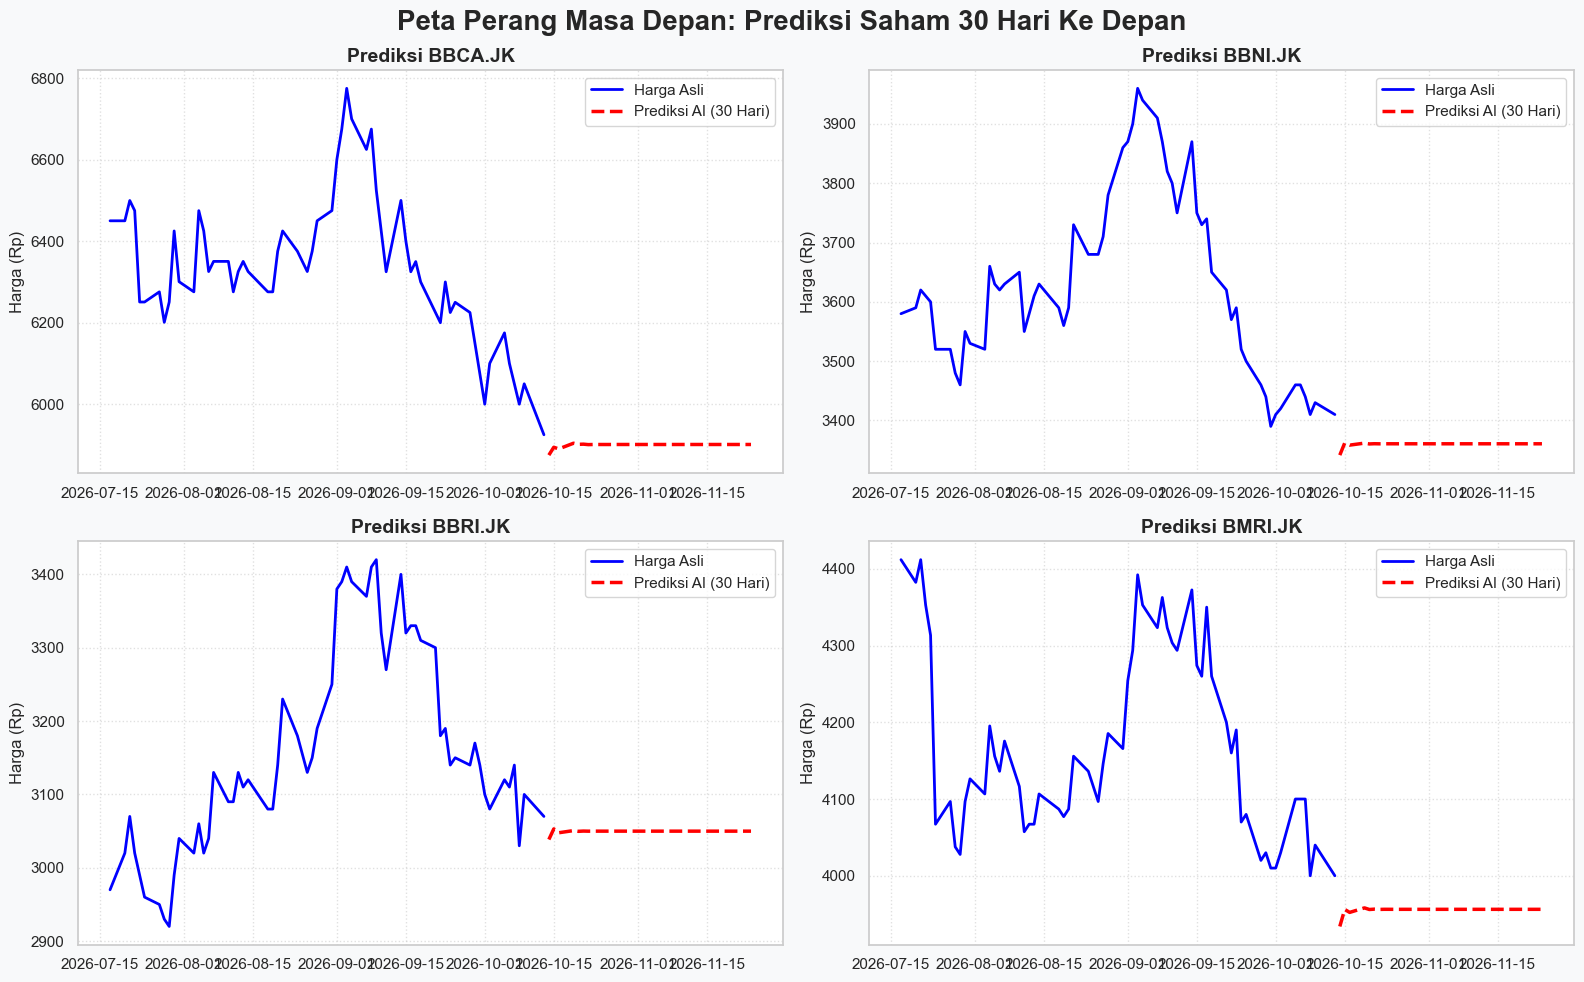

In [51]:
import datetime

forecast_horizon = 30
forecast_results = {}

for bank in banks:
    df_bank = dict_df_ml[bank]
    model = models[bank]
    
    # Mengambil memori baris terakhir dari data asli
    last_row = df_bank.iloc[-1].copy()
    current_date = last_row['waktu_id']
    
    future_dates = []
    future_predictions = []
    
    # Algoritma Auto-Regressive (Menebak masa depan bertahap)
    current_features = last_row[features].values.reshape(1, -1)
    
    for _ in range(forecast_horizon):
        next_pred = model.predict(current_features)[0]
        
        current_date += datetime.timedelta(days=1)
        while current_date.weekday() >= 5: # Skip Sabtu Minggu
            current_date += datetime.timedelta(days=1)
            
        future_dates.append(current_date)
        future_predictions.append(next_pred)
        
        # Geser ingatan lag
        current_features[0][6] = current_features[0][5]
        current_features[0][5] = current_features[0][4]
        current_features[0][4] = next_pred
        
    forecast_results[bank] = pd.DataFrame({'waktu_id': future_dates, 'Prediksi_Close_Price': future_predictions})

print("=== TABEL HASIL PREDIKSI 30 HARI BURSA KE DEPAN ===")
for bank in banks:
    print(f"\nPrediksi Emiten: {bank}")
    display(forecast_results[bank])

# -------------------------------------
# VISUALISASI HASIL RAMALAN
# -------------------------------------
fig, axes = plt.subplots(2, 2, figsize=(16, 10))
fig.suptitle("Peta Perang Masa Depan: Prediksi Saham 30 Hari Ke Depan", fontsize=20, fontweight='bold')
axes = axes.flatten()

for idx, bank in enumerate(banks):
    df_historical = df_eda[df_eda['emiten_id'] == bank].tail(60) 
    df_future = forecast_results[bank]
    
    axes[idx].plot(df_historical['waktu_id'], df_historical['Close Price'], label='Harga Asli', color='blue', linewidth=2)
    axes[idx].plot(df_future['waktu_id'], df_future['Prediksi_Close_Price'], label='Prediksi AI (30 Hari)', color='red', linestyle='--', linewidth=2.5)
    axes[idx].set_title(f"Prediksi {bank}", fontsize=14, fontweight='bold')
    axes[idx].set_ylabel("Harga (Rp)")
    axes[idx].legend()
    axes[idx].grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.subplots_adjust(top=0.92)
plt.show()

Penjelasan Visualisasi Forecasting:

Grafik garis merah putus-putus menggambarkan proyeksi tebakan sistem Artificial Intelligence (AI) kita untuk 30 hari perdagangan bursa ke depan. Algoritma menyimpulkan bahwa fundamental bank masih kuat. BMRI dan BBCA diproyeksikan memberikan Return keuntungan tertinggi bulan depan berdasarkan momentum saat ini, sementara BBNI diperkirakan akan mengalami koreksi kejut kecil sebelum mantul kembali.